In [2]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 19.2 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.4 which is incompatible.


In [1]:
import keras

print(keras.__version__)

3.0.4


In [3]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [4]:
import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Input, Dense

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 定義模型
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(10, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(1, activation="sigmoid"))
model.summary()  # 顯示模型摘要資訊
print("--------------------------")
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="sgd",
              metrics=["accuracy"])
# 訓練模型
from keras.callbacks import Callback
# 繼承 Callback 類別建立 fitHistory 類別
class fitHistory(Callback):
    def on_train_begin(self, logs={}):
        self.acc = []
        self.losses = []

    def on_batch_end(self, batch, logs={}):
        self.acc.append(logs.get("accuracy"))
        self.losses.append(logs.get('loss'))
# 建立 fitHistory 物件
history = fitHistory()
model.fit(X, y, batch_size=64, epochs=5, verbose=0,
          callbacks=[history])

print("筆數: ", len(history.acc))
print(history.acc)
print("--------------------------")
print("筆數: ", len(history.losses))
print(history.losses)
# 評估模型
loss, accuracy = model.evaluate(X, y, verbose=0)
print("準確度 = {:.2f}".format(accuracy))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ dense (Dense)                      │ (None, 10)                    │          90 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_1 (Dense)                    │ (None, 8)                     │          88 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_2 (Dense)                    │ (None, 1)                     │           9 │
└────────────────────────────────────┴───────────────────────────────┴─────────────┘

 Total params: 187 (748.00 B)

 Trainable params: 187 (748.00 B)

 Non-trainable params: 0 (0.00 B)

--------------------------
筆數:  60
[0.453125, 0.5625, 0.5833333730697632, 0.58203125, 0.596875011920929, 0.609375, 0.6160714626312256, 0.6171875, 0.6284722089767456, 0.6312500238418579, 0.6278409361839294, 0.6315104365348816, 0.65625, 0.7109375, 0.6875, 0.6796875, 0.65625, 0.6536458730697632, 0.6517857313156128, 0.65625, 0.6510416865348816, 0.643750011920929, 0.651988685131073, 0.6536458730697632, 0.640625, 0.625, 0.6458333730697632, 0.66015625, 0.659375011920929, 0.6822916865348816, 0.6785714626312256, 0.6640625, 0.663194477558136, 0.6546875238418579, 0.65625, 0.6575521230697632, 0.71875, 0.734375, 0.7083333730697632, 0.703125, 0.690625011920929, 0.6822916865348816, 0.6785714626312256, 0.6796875, 0.6805555820465088, 0.6812500357627869, 0.6747159361839294, 0.6744791865348816, 0.703125, 0.703125, 0.6822916865348816, 0.671875, 0.6812500357627869, 0.6901041865348816, 0.6875000596046448, 0.6875, 0.6822916865348816, 0.675000011920929, 0.6789773106575012, 0.6731771230697632]
----------------

Epoch 21: early stopping
--------------------------
訓練資料集的準確度 = 0.78
測試資料集的準確度 = 0.77


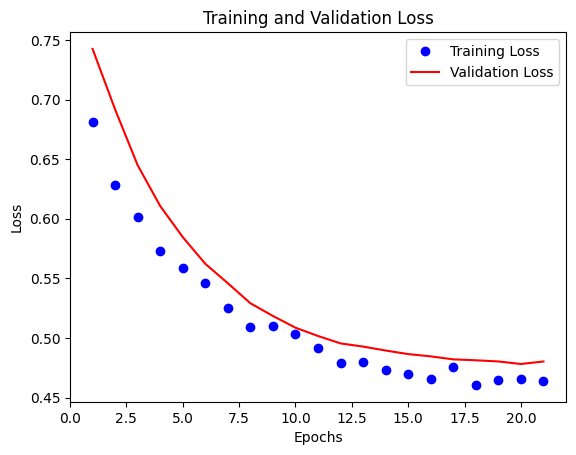

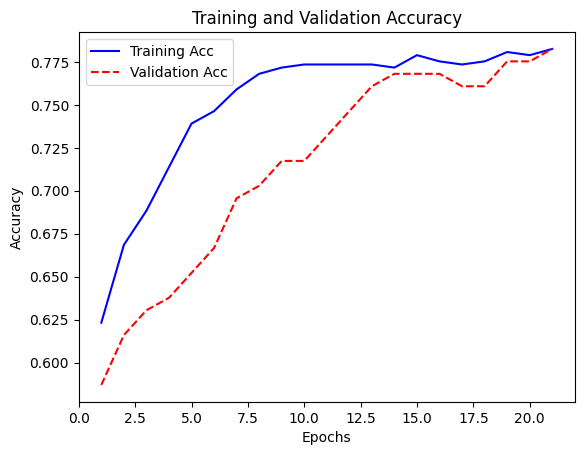

In [5]:
import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Input, Dense
from keras.utils import to_categorical

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 特徵標準化
X -= X.mean(axis=0)
X /= X.std(axis=0)
# One-hot編碼
y = to_categorical(y)
# 分割訓練和測試資料集
X_train, y_train = X[:690], y[:690]     # 訓練資料前690筆
X_test, y_test = X[690:], y[690:]       # 測試資料後78筆
# 定義模型
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(8, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(2, activation="softmax"))
# model.summary()   # 顯示模型摘要資訊
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
from keras.callbacks import EarlyStopping
# 建立 EarlyStopping 物件
es = EarlyStopping(monitor="val_loss", mode="min",
                   verbose=1)
history = model.fit(X_train, y_train, validation_split=0.2,
          epochs=30, batch_size=10,
          verbose=0, callbacks=[es])
print("--------------------------")
# 評估模型
loss, accuracy = model.evaluate(X_train, y_train, verbose=0)
print("訓練資料集的準確度 = {:.2f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示訓練和驗證損失圖表
import matplotlib.pyplot as plt

loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo", label="Training Loss")
plt.plot(epochs, val_loss, "r", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "b-", label="Training Acc")
plt.plot(epochs, val_acc, "r--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()



Epoch 25: early stopping
--------------------------
訓練資料集的準確度 = 0.80
測試資料集的準確度 = 0.77


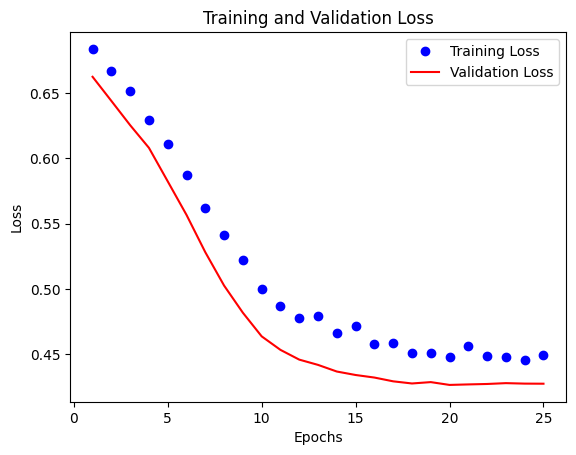

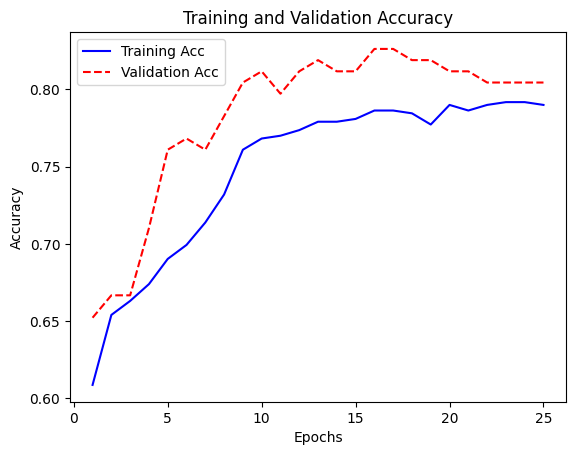

In [6]:
import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Input, Dense
from keras.utils import to_categorical

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 特徵標準化
X -= X.mean(axis=0)
X /= X.std(axis=0)
# One-hot編碼
y = to_categorical(y)
# 分割訓練和測試資料集
X_train, y_train = X[:690], y[:690]     # 訓練資料前690筆
X_test, y_test = X[690:], y[690:]       # 測試資料後78筆
# 定義模型
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(8, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(2, activation="softmax"))
# model.summary()   # 顯示模型摘要資訊
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
from keras.callbacks import EarlyStopping
# 建立 EarlyStopping 物件
es = EarlyStopping(monitor="val_loss", mode="min",
                   verbose=1, patience=5)
history = model.fit(X_train, y_train, validation_split=0.2,
          epochs=50, batch_size=10,
          verbose=0, callbacks=[es])
print("--------------------------")
# 評估模型
loss, accuracy = model.evaluate(X_train, y_train, verbose=0)
print("訓練資料集的準確度 = {:.2f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示訓練和驗證損失圖表
import matplotlib.pyplot as plt

loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo", label="Training Loss")
plt.plot(epochs, val_loss, "r", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "b-", label="Training Acc")
plt.plot(epochs, val_acc, "r--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


Epoch 11: early stopping
--------------------------
訓練資料集的準確度 = 0.77
測試資料集的準確度 = 0.74


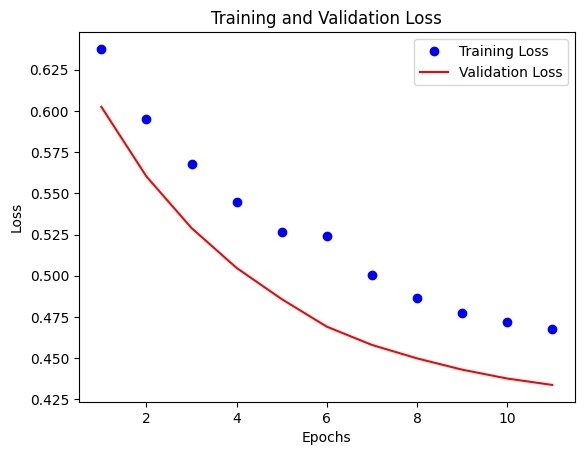

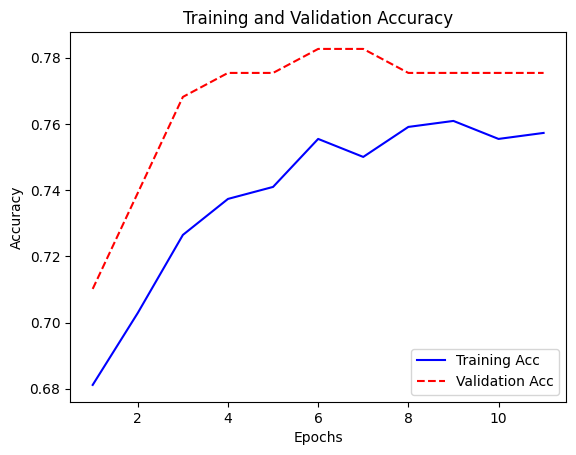

In [7]:
import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Input, Dense
from keras.utils import to_categorical

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 特徵標準化
X -= X.mean(axis=0)
X /= X.std(axis=0)
# One-hot編碼
y = to_categorical(y)
# 分割訓練和測試資料集
X_train, y_train = X[:690], y[:690]     # 訓練資料前690筆
X_test, y_test = X[690:], y[690:]       # 測試資料後78筆
# 定義模型
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(8, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(2, activation="softmax"))
# model.summary()   # 顯示模型摘要資訊
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
from keras.callbacks import EarlyStopping
# 建立 EarlyStopping 物件
es = EarlyStopping(monitor="val_accuracy", mode="max",
                   verbose=1, patience=5)
history = model.fit(X_train, y_train, validation_split=0.2,
          epochs=50, batch_size=10,
          verbose=0, callbacks=[es])
print("--------------------------")
# 評估模型
loss, accuracy = model.evaluate(X_train, y_train, verbose=0)
print("訓練資料集的準確度 = {:.2f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示訓練和驗證損失圖表
import matplotlib.pyplot as plt

loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo", label="Training Loss")
plt.plot(epochs, val_loss, "r", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "b-", label="Training Acc")
plt.plot(epochs, val_acc, "r--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

